# QEC符号族からグラフ状態のサンプルを作る

`tutorial.ipynb` の続編。`qec_families.py` の生成関数を使って、符号 → 論理ゼロ状態 → グラフ＋局所Clifford → 検証 → 保存まで実行する。

- **回転表面符号**：任意の奇数距離（3以上）。目標の **d=25,27,29** も実行する。
- **通常の平面表面符号・HGP**：`ldpc` / `bposd` で構成。
- **BB**：周期サイズ・多項式から生成。公開5例のプリセットも用意。
- **Mitten**：著者の150・200・300量子ビット例を同梱。実行時のネット接続は不要。
- **Color**：4.8.8 / 6.6.6を任意の奇数距離から生成。MQTの追加インストール不要。
- **Kasai Code（Zhaoらの例）**：一般APM係数から生成し、Zhao論文の1152・2304量子ビット例も再構成。
- **Semi-hyperbolic Color**：Bolza基礎タイリングを任意のLで細分化。
- **代数符号**：小規模Quantum Reed–Mullerと、Quantum MDS Reed–Solomonのqubit展開。

対象は全論理量子ビットの $|0\rangle_L$。距離の根拠と状態等価性検証は別々に記録する。LC最適化はここでは実行しない。


## 0. 実行環境

旧notebookの `ldpc==0.1.60` / `bposd==1.6` と分け、Python 3.11以上の新しい環境を推奨。
リポジトリのルートで、次を実行してそのカーネルを選ぶ。

```bash
python3 -m venv .venv-tutorial2
.venv-tutorial2/bin/python -m pip install -r src/requirements-tutorial2.txt
.venv-tutorial2/bin/python -m ipykernel install --user --name stabilizer-tutorial2 --display-name "QEC tutorial2"
```

共通CSS処理はquantumgizmosの `ldpc==2.4.1` / `bposd==2.1`。ColorもKasaiもこの環境で実行できる。


In [1]:
# src/から実行する場合：必要なときだけ次の行のコメントを外す
# ! pip install -r requirements-tutorial2.txt

# リポジトリのルートから実行する場合はこちら
# ! pip install -r src/requirements-tutorial2.txt

In [2]:
from pathlib import Path
import sys
from importlib.metadata import version

# カーネルの開始ディレクトリがルートでもsrcでも動く。
CWD = Path.cwd().resolve()
SRC = CWD if (CWD / "qec_families.py").is_file() else CWD / "src"
if not (SRC / "qec_families.py").is_file():
    raise RuntimeError("リポジトリのルートまたはsrcから実行してください")
sys.path.insert(0, str(SRC))
REPO = SRC.parent

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from qec_families import (
    make_rotated_surface_code, make_planar_surface_code, make_hgp_code,
    make_bb_code, make_bb_preset, BB_PRESETS, load_mitten_code,
    make_color_code, load_css_code, make_graph_sample, export_graph_sample,
    make_regular_hgp_code, make_hgp_preset, make_kasai_code, make_kasai_preset,
    make_quantum_reed_muller_code, make_quantum_reed_solomon_code,
    make_semi_hyperbolic_color_code,
)

for package in ["ldpc", "bposd", "stim", "qiskit", "numpy", "scipy"]:
    print(f"{package}: {version(package)}")

ldpc: 2.4.1
bposd: 2.1
stim: 1.16.0
qiskit: 2.6.2
numpy: 2.4.6
scipy: 1.17.1


## 1. 共通処理：論理ゼロ状態のグラフと検証結果

Hx,Hzの可換性とrank、論理Zの独立性を生成時に検証する。さらに**元の状態生成元すべて**に対してStimとQiskitの期待値が+1であることを確認する。
`sample.decomposition.graph` が最適化に渡すNetworkXグラフ。

このnotebookの `seconds` は、符号の構成後に行う状態生成・グラフ変換・両ライブラリ検証の時間。行列構成時間は含まない。


In [3]:
samples = {}

def build_sample(key, instance):
    sample = make_graph_sample(instance, verify_qiskit=True)
    samples[key] = sample
    m = sample.metrics
    print(f"{key:26s} {instance.parameters:18s} E={m['edges']:6d} "
          f"maxdeg={m['max_degree']:4d} "
          f"Stim={sample.checks['stim']} Qiskit={sample.checks['qiskit']} "
          f"seconds={m['generation_and_verification_seconds']:.3f}")
    return sample

def summary(keys):
    lines = ["| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |",
             "|---|---|---|---:|---:|---|---:|---:|"]
    for key in keys:
        s = samples[key]
        m = s.metrics
        lines.append(f"| {key} | {s.code.parameters} | {s.code.distance_status} | "
                     f"{m['edges']} | {m['max_degree']} | {m['bipartite']} | "
                     f"{m['triangles']} | {m['improving_lc_vertices']} |")
    display(Markdown("\n".join(lines)))

example = build_sample("rotated_d3", make_rotated_surface_code(3))
print("\n局所Clifford:")
print(example.decomposition.local_clifford_circuit)

rotated_d3                 [[9,1,3]]          E=    15 maxdeg=   6 Stim=True Qiskit=True seconds=0.267

局所Clifford:
X 4 6
Y 2
Z 0 3 7
S 1 2
H 0 3 5 7 8
S 0


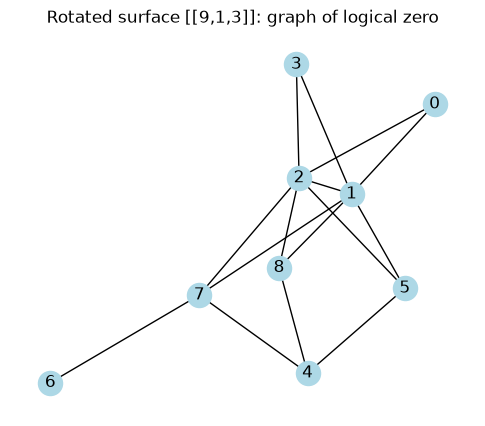

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
nx.draw(example.decomposition.graph, pos=nx.spring_layout(example.decomposition.graph, seed=0),
        with_labels=True, node_color="lightblue", ax=ax)
ax.set_title("Rotated surface [[9,1,3]]: graph of logical zero")
plt.show()

## 2. 回転表面符号：距離を変えて生成

`make_rotated_surface_code(d)` は距離別の固定行列テーブルを参照せず、格子の内側と境界のチェックを生成する。データ量子ビットは行優先で $q=rd+c$。

以下は **d=25,27,29を含む**系列。各サイズでStim/Qiskit検証を行うため、環境によっては時間がかかる。まず試す場合は `DISTANCES = [3,5,7]` に変更できる。グラフの辺数はStimの版と生成元順序に依存する。


表面符号のチェック重みは最大4で一定。一方、グラフ状態への変換は生成元の積と局所Cliffordを用いるので、変換後の次数は同じ量ではない。以下では両方を表示する。

In [5]:
DISTANCES = [3, 5, 7, 9, 11, 13, 15, 19, 21, 25, 27, 29]
rotated_keys = []
for d in DISTANCES:
    key = f"rotated_d{d}"
    if key not in samples:
        build_sample(key, make_rotated_surface_code(d))
    rotated_keys.append(key)
summary(rotated_keys)

rotated_d5                 [[25,1,5]]         E=    59 maxdeg=  13 Stim=True Qiskit=True seconds=0.006
rotated_d7                 [[49,1,7]]         E=   182 maxdeg=  24 Stim=True Qiskit=True seconds=0.011
rotated_d9                 [[81,1,9]]         E=   425 maxdeg=  34 Stim=True Qiskit=True seconds=0.025
rotated_d11                [[121,1,11]]       E=   790 maxdeg=  36 Stim=True Qiskit=True seconds=0.051


rotated_d13                [[169,1,13]]       E=  1303 maxdeg=  59 Stim=True Qiskit=True seconds=0.090


rotated_d15                [[225,1,15]]       E=  2287 maxdeg=  79 Stim=True Qiskit=True seconds=0.180


rotated_d19                [[361,1,19]]       E=  4354 maxdeg=  85 Stim=True Qiskit=True seconds=0.492


rotated_d21                [[441,1,21]]       E=  5656 maxdeg=  99 Stim=True Qiskit=True seconds=0.757


rotated_d25                [[625,1,25]]       E=  9211 maxdeg= 136 Stim=True Qiskit=True seconds=1.587


rotated_d27                [[729,1,27]]       E= 12041 maxdeg= 130 Stim=True Qiskit=True seconds=2.107


rotated_d29                [[841,1,29]]       E= 14928 maxdeg= 162 Stim=True Qiskit=True seconds=2.998


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| rotated_d3 | [[9,1,3]] | construction | 15 | 6 | False | 5 | 2 |
| rotated_d5 | [[25,1,5]] | construction | 59 | 13 | False | 37 | 4 |
| rotated_d7 | [[49,1,7]] | construction | 182 | 24 | False | 178 | 12 |
| rotated_d9 | [[81,1,9]] | construction | 425 | 34 | False | 778 | 33 |
| rotated_d11 | [[121,1,11]] | construction | 790 | 36 | False | 1940 | 40 |
| rotated_d13 | [[169,1,13]] | construction | 1303 | 59 | False | 3667 | 47 |
| rotated_d15 | [[225,1,15]] | construction | 2287 | 79 | False | 9811 | 120 |
| rotated_d19 | [[361,1,19]] | construction | 4354 | 85 | False | 21466 | 176 |
| rotated_d21 | [[441,1,21]] | construction | 5656 | 99 | False | 24071 | 122 |
| rotated_d25 | [[625,1,25]] | construction | 9211 | 136 | False | 44721 | 196 |
| rotated_d27 | [[729,1,27]] | construction | 12041 | 130 | False | 84507 | 334 |
| rotated_d29 | [[841,1,29]] | construction | 14928 | 162 | False | 94085 | 254 |

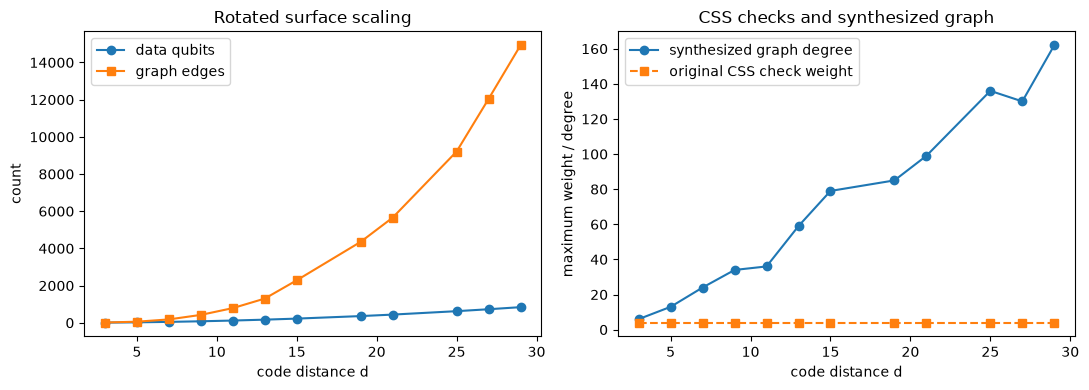

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(DISTANCES, [samples[k].code.n for k in rotated_keys], "o-", label="data qubits")
axes[0].plot(DISTANCES, [samples[k].metrics["edges"] for k in rotated_keys], "s-", label="graph edges")
axes[0].set(xlabel="code distance d", ylabel="count", title="Rotated surface scaling")
axes[0].legend()
axes[1].plot(DISTANCES, [samples[k].metrics["max_degree"] for k in rotated_keys], "o-", label="synthesized graph degree")
axes[1].plot(DISTANCES, [samples[k].metrics["max_check_weight"] for k in rotated_keys], "s--", label="original CSS check weight")
axes[1].set(xlabel="code distance d", ylabel="maximum weight / degree", title="CSS checks and synthesized graph")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. 通常の平面表面符号と回転版を区別する

反復符号同士のHGPは通常の平面表面符号 $[[2d^2-2d+1,1,d]]$。回転版の $[[d^2,1,d]]$ とは別。通常版は偶数距離も構成する。


In [7]:
planar_keys = []
for d in [3, 4, 5, 6, 7]:
    key = f"planar_d{d}"
    build_sample(key, make_planar_surface_code(d))
    planar_keys.append(key)
summary(planar_keys)

planar_d3                  [[13,1,3]]         E=    18 maxdeg=   5 Stim=True Qiskit=True seconds=0.003
planar_d4                  [[25,1,4]]         E=    48 maxdeg=   7 Stim=True Qiskit=True seconds=0.004
planar_d5                  [[41,1,5]]         E=   100 maxdeg=   9 Stim=True Qiskit=True seconds=0.007
planar_d6                  [[61,1,6]]         E=   180 maxdeg=  11 Stim=True Qiskit=True seconds=0.014
planar_d7                  [[85,1,7]]         E=   294 maxdeg=  13 Stim=True Qiskit=True seconds=0.024


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| planar_d3 | [[13,1,3]] | construction | 18 | 5 | True | 0 | 0 |
| planar_d4 | [[25,1,4]] | construction | 48 | 7 | True | 0 | 0 |
| planar_d5 | [[41,1,5]] | construction | 100 | 9 | True | 0 | 0 |
| planar_d6 | [[61,1,6]] | construction | 180 | 11 | True | 0 | 0 |
| planar_d7 | [[85,1,7]] | construction | 294 | 13 | True | 0 | 0 |

## 4. BB：既知例と一般多項式生成

[Bravyi et al.](https://arxiv.org/abs/2308.07915) の公開例。距離は文献値であり、このnotebookで最小距離を探索した結果ではない。
周期シフトの二変数多項式から $H_X=[A|B]$, $H_Z=[B^T|A^T]$ を構成する。MQTのオブジェクトは使わない。


In [8]:
bb_keys = []
for n in BB_PRESETS:
    key = f"bb_n{n}"
    build_sample(key, make_bb_preset(n))
    bb_keys.append(key)
summary(bb_keys)

bb_n72                     [[72,12,6]]        E=   990 maxdeg=  45 Stim=True Qiskit=True seconds=0.034
bb_n90                     [[90,8,10]]        E=  1463 maxdeg=  49 Stim=True Qiskit=True seconds=0.047


bb_n108                    [[108,8,10]]       E=  1732 maxdeg=  61 Stim=True Qiskit=True seconds=0.072


bb_n144                    [[144,12,12]]      E=  2369 maxdeg=  81 Stim=True Qiskit=True seconds=0.127


bb_n288                    [[288,12,18]]      E= 11865 maxdeg= 161 Stim=True Qiskit=True seconds=0.992


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| bb_n72 | [[72,12,6]] | literature | 990 | 45 | False | 4670 | 23 |
| bb_n90 | [[90,8,10]] | literature | 1463 | 49 | False | 7946 | 25 |
| bb_n108 | [[108,8,10]] | literature | 1732 | 61 | False | 9852 | 41 |
| bb_n144 | [[144,12,12]] | literature | 2369 | 81 | False | 11665 | 24 |
| bb_n288 | [[288,12,18]] | literature | 11865 | 161 | False | 210770 | 120 |

In [9]:
# 任意の周期サイズ・モノミアル列を入力できる。
# 各組(a,b)は x**a * y**b。以下はGrossと同じ多項式。
# custom_bb = make_bb_code(
#     l=12, m=6,
#     polynomial_a=[(3, 0), (0, 1), (0, 2)],
#     polynomial_b=[(0, 3), (1, 0), (2, 0)],
# )
# print(custom_bb.parameters, custom_bb.distance_status)
# 同じ構成でも一般関数は距離を推測しない。既知例のラベルはpreset側で付与する。
# assert custom_bb.distance is None
# build_sample("bb_custom", custom_bb)

## 5. HGP：実用例に近い成分行列を選ぶ

主系列は **bit degree 3 / check degree 4 のbiregular古典LDPC** 同士の積。全行rankなら、古典長 $n_c$ とチェック数 $m_c=3n_c/4$ に対して $N=n_c^2+m_c^2$, $K=(n_c-m_c)^2$, レート $1/25$、量子チェック重み7。
[Xu et al.](https://arxiv.org/abs/2308.08648) が中性原子で回路レベル評価した構成の参考になる。

ここでは有限回のランダム候補から、計算できる小規模古典距離、4-cycle数、スペクトルギャップの順で選ぶ。**論文と同一の行列・girth≥6・展開性は保証しない**。生成seedと実際の成分行列を保存する。
小さいkernelを全探索できる場合のみ、全行rankの対称HGPの距離公式から `distance_status="computed"` を付ける。大規模では距離を未確認とする。

より高レートな比較には `bit_degree=3, check_degree=6` も指定できる（全行rankでレート1/5、チェック重み9）。距離やデコード性能も比較して選ぶ。


In [10]:
hgp_keys = []
for num_bits in [12, 16, 20, 24]:
    key = f"hgp_regular_{num_bits}"
    instance = make_regular_hgp_code(num_bits, seed=0, candidates=16)
    build_sample(key, instance)
    print("  seed diagnostics:", instance.metadata["classical_seed"])
    hgp_keys.append(key)
summary(hgp_keys)

# 任意の古典チェック行列からの構成も可能：make_hgp_code(h1, h2)


hgp_regular_12             [[225,9,6]]        E=  6133 maxdeg= 108 Stim=True Qiskit=True seconds=0.266
  seed diagnostics: {'rows': 9, 'cols': 12, 'rank': 9, 'row_weights': [4], 'column_weights': [3], 'four_cycles': 10, 'connected': True, 'spectral_gap': 0.7373692942985008, 'classical_distance': 6}


hgp_regular_16             [[400,16,6]]       E= 20318 maxdeg= 196 Stim=True Qiskit=True seconds=1.063
  seed diagnostics: {'rows': 12, 'cols': 16, 'rank': 12, 'row_weights': [4], 'column_weights': [3], 'four_cycles': 5, 'connected': True, 'spectral_gap': 0.7400918231106433, 'classical_distance': 6}


hgp_regular_20             [[625,25,6]]       E= 61641 maxdeg= 323 Stim=True Qiskit=True seconds=3.424
  seed diagnostics: {'rows': 15, 'cols': 20, 'rank': 15, 'row_weights': [4], 'column_weights': [3], 'four_cycles': 8, 'connected': True, 'spectral_gap': 0.7367498123722287, 'classical_distance': 6}


hgp_regular_24             [[900,36,8]]       E= 12912 maxdeg=  52 Stim=True Qiskit=True seconds=5.728
  seed diagnostics: {'rows': 18, 'cols': 24, 'rank': 18, 'row_weights': [4], 'column_weights': [3], 'four_cycles': 5, 'connected': True, 'spectral_gap': 0.5181680584297736, 'classical_distance': 8}


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| hgp_regular_12 | [[225,9,6]] | computed | 6133 | 108 | False | 74852 | 92 |
| hgp_regular_16 | [[400,16,6]] | computed | 20318 | 196 | False | 434252 | 125 |
| hgp_regular_20 | [[625,25,6]] | computed | 61641 | 323 | False | 2392833 | 297 |
| hgp_regular_24 | [[900,36,8]] | computed | 12912 | 52 | True | 0 | 0 |

### 公開されたPEG / SA成分との比較

[Freire–Delfosse–Leverrier](https://arxiv.org/abs/2501.09622) の付属15×20古典行列を同梱。`HGP(H,H)` でともに $[[625,25]]$、古典kernelを全探索するとPEGは距離6、SAは距離8。
SAは**消失ノイズに対する性能で選択**されたもので、回路ノイズでも最良という意味ではない。4-cycleの少なさだけで選ぶ場合との対照になる。


In [11]:
published_hgp_keys = []
for method in ["PEG", "SA"]:
    key = f"hgp625_{method.lower()}"
    instance = make_hgp_preset(method)
    build_sample(key, instance)
    print("  seed diagnostics:", instance.metadata["classical_seed"])
    published_hgp_keys.append(key)
summary(published_hgp_keys)


hgp625_peg                 [[625,25,6]]       E= 61034 maxdeg= 306 Stim=True Qiskit=True seconds=3.271
  seed diagnostics: {'rows': 15, 'cols': 20, 'rank': 15, 'row_weights': [3, 4, 5], 'column_weights': [3], 'four_cycles': 0, 'connected': True, 'spectral_gap': 0.9334276839724511, 'classical_distance': 6}


hgp625_sa                  [[625,25,8]]       E=  7788 maxdeg=  48 Stim=True Qiskit=True seconds=2.285
  seed diagnostics: {'rows': 15, 'cols': 20, 'rank': 15, 'row_weights': [3, 4], 'column_weights': [2, 3], 'four_cycles': 8, 'connected': True, 'spectral_gap': 0.5160873491616154, 'classical_distance': 8}


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| hgp625_peg | [[625,25,6]] | computed | 61034 | 306 | False | 2514929 | 323 |
| hgp625_sa | [[625,25,8]] | computed | 7788 | 48 | True | 0 | 0 |

## 6. Mitten：著者の公開行列から作る

[a7b/yarn](https://github.com/a7b/yarn) の150・200・300データ量子ビット例を `src/data/mitten/` に同梱。元の行列は変更せず、commit・URL・SHA-256・MITライセンスを保存した。
ロード時にハッシュ、チェックの可換性、論理Zの独立性、付属論理X/Zのペアリングを検証する。距離は文献値で、独立した距離認証ではない。

これは公開インスタンスの読込み。任意距離からのmitten生成や新規符号の探索はまだ行わない。


In [12]:
mitten_keys = []
for n in [150, 200, 300]:
    key = f"mitten_n{n}"
    build_sample(key, load_mitten_code(n))
    mitten_keys.append(key)
summary(mitten_keys)
print("Upstream commit:", samples[mitten_keys[0]].code.metadata["commit"])

mitten_n150                [[150,30,10]]      E=  3120 maxdeg=  90 Stim=True Qiskit=True seconds=0.195


mitten_n200                [[200,40,12]]      E=  2608 maxdeg=  38 Stim=True Qiskit=True seconds=0.296


mitten_n300                [[300,60,14]]      E= 12079 maxdeg= 170 Stim=True Qiskit=True seconds=1.193


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| mitten_n150 | [[150,30,10]] | literature | 3120 | 90 | False | 19191 | 44 |
| mitten_n200 | [[200,40,12]] | literature | 2608 | 38 | True | 0 | 0 |
| mitten_n300 | [[300,60,14]] | literature | 12079 | 170 | False | 144716 | 73 |

Upstream commit: 1b58edd24e19b6b5da6814fd3a74ebb376b6e90f


## 7. Color：距離指定で4.8.8 / 6.6.6を生成

`make_color_code(d, lattice=...)` は任意の奇数 $d\ge3$ に対応。4.8.8は $n=(d^2+2d-1)/2$、6.6.6は $n=(3d^2+1)/4$。ともに $k=1$, $H_X=H_Z$。

MQTのMITライセンスの格子生成アルゴリズムを `color_lattices.py` に取り込み、出典commitとライセンスを同梱した。MQT自体のインストールは不要。共通CSS検証とグラフ変換は他の符号族と同じ。


In [13]:
color_keys = []
for lattice in ["4.8.8", "6.6.6"]:
    for d in [3, 5, 7, 9, 11, 13]:
        key = f"color_{lattice}_d{d}"
        build_sample(key, make_color_code(d, lattice=lattice))
        color_keys.append(key)
summary(color_keys)


color_4.8.8_d3             [[7,1,3]]          E=     9 maxdeg=   3 Stim=True Qiskit=True seconds=0.003
color_4.8.8_d5             [[17,1,5]]         E=    66 maxdeg=  13 Stim=True Qiskit=True seconds=0.005
color_4.8.8_d7             [[31,1,7]]         E=   119 maxdeg=  15 Stim=True Qiskit=True seconds=0.015
color_4.8.8_d9             [[49,1,9]]         E=   278 maxdeg=  26 Stim=True Qiskit=True seconds=0.015
color_4.8.8_d11            [[71,1,11]]        E=   334 maxdeg=  28 Stim=True Qiskit=True seconds=0.022
color_4.8.8_d13            [[97,1,13]]        E=   752 maxdeg=  51 Stim=True Qiskit=True seconds=0.045
color_6.6.6_d3             [[7,1,3]]          E=    10 maxdeg=   4 Stim=True Qiskit=True seconds=0.003
color_6.6.6_d5             [[19,1,5]]         E=    53 maxdeg=  12 Stim=True Qiskit=True seconds=0.005
color_6.6.6_d7             [[37,1,7]]         E=   178 maxdeg=  20 Stim=True Qiskit=True seconds=0.010
color_6.6.6_d9             [[61,1,9]]         E=   640 maxdeg=  37 Stim=T

color_6.6.6_d11            [[91,1,11]]        E=   876 maxdeg=  44 Stim=True Qiskit=True seconds=0.046


color_6.6.6_d13            [[127,1,13]]       E=  1688 maxdeg=  64 Stim=True Qiskit=True seconds=0.086


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| color_4.8.8_d3 | [[7,1,3]] | construction | 9 | 3 | True | 0 | 0 |
| color_4.8.8_d5 | [[17,1,5]] | construction | 66 | 13 | False | 114 | 16 |
| color_4.8.8_d7 | [[31,1,7]] | construction | 119 | 15 | False | 182 | 15 |
| color_4.8.8_d9 | [[49,1,9]] | construction | 278 | 26 | False | 612 | 19 |
| color_4.8.8_d11 | [[71,1,11]] | construction | 334 | 28 | False | 432 | 14 |
| color_4.8.8_d13 | [[97,1,13]] | construction | 752 | 51 | False | 2271 | 31 |
| color_6.6.6_d3 | [[7,1,3]] | construction | 10 | 4 | False | 2 | 1 |
| color_6.6.6_d5 | [[19,1,5]] | construction | 53 | 12 | False | 34 | 3 |
| color_6.6.6_d7 | [[37,1,7]] | construction | 178 | 20 | False | 241 | 10 |
| color_6.6.6_d9 | [[61,1,9]] | construction | 640 | 37 | False | 3370 | 37 |
| color_6.6.6_d11 | [[91,1,11]] | construction | 876 | 44 | False | 2725 | 35 |
| color_6.6.6_d13 | [[127,1,13]] | construction | 1688 | 64 | False | 8187 | 47 |

## 8. Semi-hyperbolic Color：基礎タイリングを細分化

[Higgott et al., arXiv:2610.03682v1, Supplement S2](https://arxiv.org/abs/2610.03682) の静的Color構成。Bolza曲面の8.8.8-16基礎三角形タイリングを用い、各三角形を辺長LのEuclidean三角格子（$L^2$個の小三角形）へ細分化する。その双対の頂点をデータqubit、面をX/Zチェックにする。

`make_semi_hyperbolic_color_code(L, base_tiling="bolza16")` は任意の整数L≥1から生成し、$n=16L^2$, $k=8$。基礎タイリングを固定して大域構造を保ったサイズ系列になる。Lに応じて格子とチェック行列を生成する。

| L | パラメータ | 距離の根拠 |
|---|---|---|
| 1 | [[16,8,2]] | 文献値（細分化前のhyperbolic例） |
| 2 | [[64,8,6]] | 文献値。テストでもmeet-in-the-middleにより距離6を独立確認 |
| 3 | [[144,8,8]] | 文献値 |
| 4 | [[256,8,12]] | 文献値 |
| 5以降 | [[16L²,8,?]] | 未確認。Lから距離を推測しない |

各qubitはXチェック3個・Zチェック3個に参加する。重み8のcornerチェックは常に6個、それ以外は重み6。メタデータには細分化L、基礎隣接関係、曲面のgenus、チェック色、qubitの所属する基礎三角形（K=1モジュール）を保存する。

**基礎データの出典**：論文が共用すると記す著者の旧Floquetデータから、16三角形の色付き隣接関係だけを取得した。Floquetの測定チェック・論理演算子・距離を静的CSSへ流用していない。公開commitとハッシュを固定し、3つの反可換なinvolutionで生成する16元群のCayleyグラフとも色を保った同型を検証した。

別の基礎タイリングは `base_tiling={"name": ..., "neighbors": ...}` で渡せる。neighbors[t][i]は、三角形tの色iの頂点の対辺を越えた隣の三角形。閉曲面の条件を検証し、カスタム入力にはプリセットの文献距離を自動付与しない。


In [14]:
semi_color_keys = []
for length in [1, 2, 3, 4, 5]:
    key = f"semi_color_bolza16_L{length}"
    instance = make_semi_hyperbolic_color_code(length)
    build_sample(key, instance)
    print("  genus:", instance.metadata["genus"],
          "max check weight:", samples[key].metrics["max_check_weight"])
    semi_color_keys.append(key)
summary(semi_color_keys)


semi_color_bolza16_L1      [[16,8,2]]         E=    28 maxdeg=   7 Stim=True Qiskit=True seconds=0.003
  genus: 2 max check weight: 8
semi_color_bolza16_L2      [[64,8,6]]         E=   555 maxdeg=  41 Stim=True Qiskit=True seconds=0.020
  genus: 2 max check weight: 8


semi_color_bolza16_L3      [[144,8,8]]        E=  3115 maxdeg=  81 Stim=True Qiskit=True seconds=0.100
  genus: 2 max check weight: 8


semi_color_bolza16_L4      [[256,8,12]]       E=  6959 maxdeg= 129 Stim=True Qiskit=True seconds=0.298
  genus: 2 max check weight: 8


semi_color_bolza16_L5      [[400,8,?]]        E= 24712 maxdeg= 203 Stim=True Qiskit=True seconds=0.920
  genus: 2 max check weight: 8


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| semi_color_bolza16_L1 | [[16,8,2]] | literature | 28 | 7 | True | 0 | 0 |
| semi_color_bolza16_L2 | [[64,8,6]] | literature | 555 | 41 | False | 1454 | 27 |
| semi_color_bolza16_L3 | [[144,8,8]] | literature | 3115 | 81 | False | 24837 | 59 |
| semi_color_bolza16_L4 | [[256,8,12]] | literature | 6959 | 129 | False | 62832 | 73 |
| semi_color_bolza16_L5 | [[400,8,?]] | unknown | 24712 | 203 | False | 681529 | 225 |

## 9. Kasai Code：Zhaoらのインスタンス

[Zhao et al. arXiv:2604.16209v2, Table A1](https://arxiv.org/html/2604.16209v2) の最初の2例を、記載されたアフィン置換 $x\mapsto ax+b\pmod P$ から生成する。

- $P=96$: $[[1152,580,\le12]]$
- $P=192$: $[[2304,1156,\le14]]$

同じ $n,k$ の別カタログ例と混同しない。距離は論文の**上界**であり、確定距離ではない。プリセットは係数と構成方法を固定し、一般関数 `make_kasai_code(modulus, f_maps, g_maps, active_rows=3)` は入力係数から構成して可換性・rankを検証する。新規係数の探索は含まない。

この2例は大きいので数分かかる場合がある。小さい例だけ試すなら `KASAI_SIZES = [1152]` に変更できる。


**実装の出典**：APM構成の原型はKasaiだが、この2つのプリセットの係数はZhaoらの中性原子向け派生例。Kasai原論文の9216量子ビット例や著者探索プログラムの再現ではない。一般APM生成関数は係数を入力して使えるが、係数探索は行わない。

**論文中の表記**：名称は “Kasai Code” に統一する。初出では[Kasaiの原構成](https://arxiv.org/abs/2601.08824)と、使用する有限サイズインスタンスの出典であるZhaoらの両方を引用する。例：“We use Kasai codes [Kasai], with the finite-size instances reported by Zhao et al. [Zhao].” APM（affine permutation matrices）によるCSS構成は手法として説明する。

In [15]:
KASAI_SIZES = [1152, 2304]
kasai_keys = []
for n_qubits in KASAI_SIZES:
    key = f"kasai_n{n_qubits}"
    instance = make_kasai_preset(n_qubits)
    build_sample(key, instance)
    print("  max check weight:", samples[key].metrics["max_check_weight"])
    kasai_keys.append(key)
summary(kasai_keys)


kasai_n1152                  [[1152,580,<=12]]  E=142562 maxdeg= 619 Stim=True Qiskit=True seconds=28.000
  max check weight: 12


kasai_n2304                  [[2304,1156,<=14]] E=1146252 maxdeg=1215 Stim=True Qiskit=True seconds=236.012
  max check weight: 12


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| kasai_n1152 | [[1152,580,<=12]] | upper_bound | 142562 | 619 | False | 4728301 | 102 |
| kasai_n2304 | [[2304,1156,<=14]] | upper_bound | 1146252 | 1215 | False | 231088613 | 894 |

## 10. 代数符号

### 10.1 Quantum Reed–Muller：小規模な蒸留用符号

`make_quantum_reed_muller_code(m, order=r)` は $m>2r\ge2$ から
$[[2^m-1,1,2^{r+1}-1]]$ を生成する。[Hastings–Haah](https://arxiv.org/abs/1709.03543) のpunctured RM族の $w=0$ に対応する。

非ゼロ2進点上で、Xチェックをshortened RM(r,m)、Zチェックをshortened RM(m−r−1,m)の非定数モノミアルから構成する。

- r=1,m=3: Steane $[[7,1,3]]$。
- r=1,m=4: **15-to-1魔法状態蒸留**で重要な $[[15,1,3]]$。旧tutorialのTetrahedralと同じ符号族で、距離別テーブルではなく生成関数へ拡張した。
- r=1,m=5,6: $[[31,1,3]]$, $[[63,1,3]]$。量子ビット数を増やしてもこの系列の距離は3。
- r=2,m=5,7: $[[31,1,7]]$, $[[127,1,7]]$。距離と横断ゲートの関係を比較する。

$\nu=\lfloor(m-1)/r\rfloor$ として、物理的な一様 $R_\nu=\mathrm{diag}(1,e^{2\pi i/2^\nu})$ が論理 $R_\nu^\dagger$ を実装する。**Tが横断的なのはν≥3の場合**で、31量子ビット・距離7の例はν=2となる。

ここで生成するのは他と同じ $|0\rangle_L$ のグラフ。非Clifford魔法状態は一般にグラフ状態＋局所Cliffordでは表せないため、蒸留用符号の状態準備と、魔法状態・蒸留プロトコルの性能評価を区別する。


In [16]:
qrm_keys = []
for m, r in [(3, 1), (4, 1), (5, 1), (6, 1), (5, 2), (7, 2)]:
    key = f"qrm_m{m}_r{r}"
    instance = make_quantum_reed_muller_code(m, order=r)
    build_sample(key, instance)
    print("  transversal phase level:", instance.metadata["transversal_phase_level"],
          "transversal T:", instance.metadata["transversal_t"])
    qrm_keys.append(key)
summary(qrm_keys)


qrm_m3_r1                  [[7,1,3]]          E=     9 maxdeg=   3 Stim=True Qiskit=True seconds=0.002
  transversal phase level: 2 transversal T: False
qrm_m4_r1                  [[15,1,3]]         E=    28 maxdeg=   7 Stim=True Qiskit=True seconds=0.003
  transversal phase level: 3 transversal T: True
qrm_m5_r1                  [[31,1,3]]         E=    75 maxdeg=  15 Stim=True Qiskit=True seconds=0.007
  transversal phase level: 4 transversal T: True
qrm_m6_r1                  [[63,1,3]]         E=   186 maxdeg=  31 Stim=True Qiskit=True seconds=0.027
  transversal phase level: 5 transversal T: True
qrm_m5_r2                  [[31,1,7]]         E=   167 maxdeg=  17 Stim=True Qiskit=True seconds=0.008
  transversal phase level: 2 transversal T: False
qrm_m7_r2                  [[127,1,7]]        E=  2375 maxdeg=  73 Stim=True Qiskit=True seconds=0.118
  transversal phase level: 3 transversal T: True


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| qrm_m3_r1 | [[7,1,3]] | construction | 9 | 3 | True | 0 | 0 |
| qrm_m4_r1 | [[15,1,3]] | construction | 28 | 7 | True | 0 | 0 |
| qrm_m5_r1 | [[31,1,3]] | construction | 75 | 15 | True | 0 | 0 |
| qrm_m6_r1 | [[63,1,3]] | construction | 186 | 31 | True | 0 | 0 |
| qrm_m5_r2 | [[31,1,7]] | construction | 167 | 17 | False | 280 | 11 |
| qrm_m7_r2 | [[127,1,7]] | construction | 2375 | 73 | False | 26543 | 57 |

### 10.2 Quantum Reed–Solomon：qudit MDSとqubit展開を分ける

[Grassl–Beth–Rötteler](https://arxiv.org/abs/quant-ph/0312164) のQuantum MDS構成に対応する、GF($q=2^m$)上の自己直交GRSからCSS符号を作る。
`make_quantum_reed_solomon_code(field_degree=m, distance=d, length=n)` は $2\le m\le8$, $3\le n\le q$, $n-2(d-1)>0$ に対応。length省略時はn=q。

**元の符号は $[[n,n-2d+2,d]]_q$ で、quditのQuantum Singleton boundを飽和する。** チェック行列と評価点・列係数をメタデータに保存する。

現在のStim/Qiskitバックエンドへ渡すため、1 quditをm qubitに展開する。Xは多項式基底の座標、Zは体のトレースで得る双対座標を使い、Pauliの可換性を保つ。

- 展開後は $N=mn$, $K=m(n-2d+2)$。
- **qubit距離は $d_{binary}\ge d$**。表のdistance statusは `lower_bound`。元のqudit距離をqubitの確定距離として表示しない。
- 展開後のqubit符号がMDSとは主張しない。GF(2^m)の基底とqubit順序も固定する。
- この代数構成はLDPCではなく、QECの耐故障回路やデコード性能の再現は含まない。

d=25/29の例も含めるが、これはqudit符号の距離とqubit距離の下界。表面符号の資源見積もりをそのまま移植するものではない。


In [17]:
qrs_keys = []
# (field degree m, qudit length n, qudit distance d)
for m, n_qudits, d in [(2, 4, 2), (3, 7, 3), (3, 8, 4), (4, 16, 5),
                       (4, 16, 8), (5, 32, 9), (6, 64, 25), (6, 64, 29)]:
    key = f"qrs_gf{2**m}_n{n_qudits}_d{d}"
    instance = make_quantum_reed_solomon_code(m, d, length=n_qudits)
    parent = instance.metadata["parent_parameters"]
    print(f"Parent qudit MDS: [[{parent['n']},{parent['k']},{parent['distance']}]]_" 
          f"{parent['q']}")
    build_sample(key, instance)
    qrs_keys.append(key)
summary(qrs_keys)


Parent qudit MDS: [[4,2,2]]_4
qrs_gf4_n4_d2              [[8,4,>=2]]        E=     6 maxdeg=   3 Stim=True Qiskit=True seconds=0.002
Parent qudit MDS: [[7,3,3]]_8
qrs_gf8_n7_d3              [[21,9,>=3]]       E=    48 maxdeg=   9 Stim=True Qiskit=True seconds=0.005
Parent qudit MDS: [[8,2,4]]_8
qrs_gf8_n8_d4              [[24,6,>=4]]       E=    75 maxdeg=  11 Stim=True Qiskit=True seconds=0.005
Parent qudit MDS: [[16,8,5]]_16


qrs_gf16_n16_d5            [[64,32,>=5]]      E=   448 maxdeg=  29 Stim=True Qiskit=True seconds=0.030
Parent qudit MDS: [[16,2,8]]_16
qrs_gf16_n16_d8            [[64,8,>=8]]       E=   524 maxdeg=  23 Stim=True Qiskit=True seconds=0.042
Parent qudit MDS: [[32,16,9]]_32


qrs_gf32_n32_d9            [[160,80,>=9]]     E=  2280 maxdeg=  59 Stim=True Qiskit=True seconds=0.305
Parent qudit MDS: [[64,16,25]]_64


qrs_gf64_n64_d25           [[384,96,>=25]]    E= 17872 maxdeg= 131 Stim=True Qiskit=True seconds=5.325
Parent qudit MDS: [[64,8,29]]_64


qrs_gf64_n64_d29           [[384,48,>=29]]    E= 18792 maxdeg= 125 Stim=True Qiskit=True seconds=6.053


| name | [[n,k,d]] | distance status | edges | max degree | bipartite | triangles | improving LC vertices |
|---|---|---|---:|---:|---|---:|---:|
| qrs_gf4_n4_d2 | [[8,4,>=2]] | lower_bound | 6 | 3 | True | 0 | 0 |
| qrs_gf8_n7_d3 | [[21,9,>=3]] | lower_bound | 48 | 9 | True | 0 | 0 |
| qrs_gf8_n8_d4 | [[24,6,>=4]] | lower_bound | 75 | 11 | True | 0 | 0 |
| qrs_gf16_n16_d5 | [[64,32,>=5]] | lower_bound | 448 | 29 | True | 0 | 0 |
| qrs_gf16_n16_d8 | [[64,8,>=8]] | lower_bound | 524 | 23 | True | 0 | 0 |
| qrs_gf32_n32_d9 | [[160,80,>=9]] | lower_bound | 2280 | 59 | True | 0 | 0 |
| qrs_gf64_n64_d25 | [[384,96,>=25]] | lower_bound | 17872 | 131 | True | 0 | 0 |
| qrs_gf64_n64_d29 | [[384,48,>=29]] | lower_bound | 18792 | 125 | True | 0 | 0 |

## 11. 共著者に渡すサンプルを保存

実行するたび別のディレクトリを作り、既存データを上書きしない。`output/tutorial2/` はGitの対象外。

各サンプルには以下を保存する。

- `sample.json`：全頂点、辺リスト、距離の根拠、構成パラメータ、検証結果、ライブラリ版、各ファイルのハッシュ。
- `code.npz`：Hx,Hzと採用した全論理Z。
- `stabilizers.txt`：状態を定めるn個の独立生成元（左端がqubit 0）。
- `preparation.stim` と `local_clifford.stim`：元の論理ゼロ状態の準備回路と局所Clifford。

小さなファイルをまず確認する場合は `EXPORT_KEYS = ["rotated_d3", "bb_n144", "mitten_n150"]` に変更する。


In [18]:
from datetime import datetime, timezone
from uuid import uuid4
import json

EXPORT_KEYS = list(samples)
run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
OUTPUT = REPO / "output" / "tutorial2" / run_name
for key in EXPORT_KEYS:
    export_graph_sample(samples[key], OUTPUT / key)
print(f"Saved {len(EXPORT_KEYS)} samples to {OUTPUT}")

saved = json.loads((OUTPUT / "rotated_d3" / "sample.json").read_text())
print({key: saved[key] for key in ["name", "n", "k", "distance", "distance_status", "verification"]})
# 任意のCSS行列の読込みにも同じAPIを使える。
restored = load_css_code(OUTPUT / "rotated_d3" / "code.npz")
assert restored.n == 9 and restored.k == 1

Saved 64 samples to /Users/parton/KEIO-UCL/stabilizer_to_graph_state/output/tutorial2/20261113T235320Z_acc80db3
{'name': 'Rotated surface d=3', 'n': 9, 'k': 1, 'distance': 3, 'distance_status': 'construction', 'verification': {'stim': True, 'qiskit': True}}


## 結果の読み方

- `edges` は初期グラフのCZ数であり、最適化後の数ではない。
- `improving_lc_vertices` は一手で辺数を減らせる頂点数。0でも複数手で改善できる場合がある。
- `bipartite` と三角形数は実際のStim出力で測る。CSS由来でも、その出力が必ず二部グラフになるとは仮定しない。
- 表面符号の距離25〜29は資源見積もりとの接点。今回の準備回路自体の耐故障性を保証する値ではない。
- 同じ状態でも生成元順序・バックエンド版により辺数が変わるため、保存した生成元とバージョンを使って再現する。

- `computed` は、小規模古典kernelの全探索と全行rankの対称HGPの距離公式による。Kasaiの `upper_bound` と区別する。
- QRSのMDS性はparentのqudit metricでの主張。表のqubit distanceは下界であり、元のqudit距離と区別する。